# W51 saturated-pixel recovery: next steps explained

2026-10-22

This notebook explains the open items one at a time, so they can be read and decided on separately. Every item has the same parts:

* **In short**: the item in one or two sentences.
* **Background**: what the problem is and where it came from.
* **Proposal**: what I would do.
* **Cost**: work and cluster time.
* **Your decision**: what needs your choice.

Where the reasoning comes from earlier work, the source is named: `report_v3_training_set_20261021.ipynb` (the current training set, "v3") and `discussion_20261021.ipynb` (questions 15 and 16).

**A few terms used throughout**

* **ramp**: the 5 readouts ("groups", numbered 0-4) of a pixel during one exposure. Light keeps adding charge, so an unsaturated ramp rises in a straight line.
* **`sat_level`**: the first group in which the pipeline flags the pixel as saturated. Level 0 means flagged already in the first group.
* **label**: the "true" flux we train on, from a PSF fit to the star's unsaturated wings (`flux` column).
* **`cal_value`**: the pipeline's own flux for the same pixel, an independent check at levels 2-4.
* **`psf_share`**: the fraction of a label that comes from the fitted star rather than the background estimate; above 0.75 the labels are reliable.
* **dex**: a factor of 10 in log scale. An error of 0.1 dex is 26%, 0.3 dex is a factor 2.

## Overview

| # | item | what you decide | needs a rerun of the training set | suggested order |
| --- | --- | --- | --- | --- |
| 1 | MIRI `area_ratio` threshold | 8 (keep), 4, or 2 | no (applied when assembling) | now |
| 2 | tag level-0 pixels by type | go / no go | yes | bundle into one rerun |
| 3 | new features: NIRCam ZEROFRAME, MIRI step ratios | go / no go | ZEROFRAME yes; ratios no | bundle into one rerun |
| 4 | bad-pixel flags (NO_LIN_CORR, DEAD) | exclude or not; DEAD like HOT? | yes, to store the flags | bundle into one rerun |
| 5 | check the level-0 labels themselves | which tests, in which order | no | can start now |
| 6 | assemble the training input | cap per star | no | after 1-4 |
| 7 | evaluation protocol | held-out fraction | no | with the first model |
| 8 | small cleanups | delete one dead check; run-script queue | yes (with the rerun) | bundle into one rerun |

**Suggested path:** decide items 1, 4 and 8 now; make the code changes of items 2, 3, 4 and 8 together and rerun once (about 2.5 hours on the cluster); meanwhile start item 5, which uses the existing v3 tables; then items 6 and 7, and train a first model.

In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.table import Table

V3 = '/orange/adamginsburg/w51/TaehwaYoo/w51_sat_recover/v3'
cols = ['flux', 'local_bkg', 'cal_value', 'sat_level', 'instrument', 'wavelength', 'area_ratio', 'in_4qpm', 'psf_star_flux',
        'DN0', 'DN1', 'DN2', 'DN3', 'DN4']
frames = []
for fn in sorted(glob.glob(f'{V3}/*_ml_training.fits')):
    t = Table.read(fn)
    if len(t) == 0:
        continue
    d = pd.DataFrame({k: np.asarray(t[k]).astype(float) for k in cols})
    d['source_id'] = os.path.basename(fn) + '|' + d.psf_star_flux.round(4).astype(str)
    frames.append(d)
v3 = pd.concat(frames, ignore_index=True)
v3['inst'] = np.where(v3.instrument == 0, 'NIRCam', 'MIRI')
v3['psf_share'] = (v3.flux - v3.local_bkg) / v3.flux
good = v3[v3.psf_share > 0.75].copy()   # the label cut already decided (decision 1 of 2026-10-21)
print(f'v3: {len(v3):,} rows; after psf_share > 0.75: {len(good):,} rows')

v3: 1,342,784 rows; after psf_share > 0.75: 935,996 rows


## 1. MIRI `area_ratio` threshold

**In short.** A few MIRI stars with a large saturated region still get labels that are too high, even after the `psf_share` cut. Lowering the `area_ratio` threshold for MIRI from 8 to 4 removes them at a small cost.

**Background.** `area_ratio` compares the size of a saturated region with the size a single star of the fitted brightness would saturate:

```
area_ratio = (saturated pixels in the region) / (pixels where the fitted star model is above the cutout's 99th percentile)
```

A clean star gives about 0.2-2. A region that merges a star with nebulosity or a second star is much larger than one star can explain, so its ratio is high. Sources above 8 are skipped. That 8 was chosen from only 12 stars. The v3 check (label / `cal_value` at levels 2-4, rows with `psf_share` > 0.75) showed:

* NIRCam: the median stays at 0.99 for every ratio, so the threshold does not matter there.
* MIRI: ratios 4-8 give labels about 40% too high (median 1.38-1.45); ratios 2-4 have a correct median but 40% of rows off by more than a factor 1.5.

**The options**, computed below for MIRI rows with `psf_share` > 0.75. "Testable rows" are the level 2-4 rows where `cal_value` can check the label; the last columns describe how good the kept labels are.

In [2]:
mi = good[good.inst == 'MIRI'].copy()
mi['ratio'] = mi.flux / mi.cal_value
testable = np.isfinite(mi.ratio) & (mi.cal_value > 0) & mi.sat_level.between(2, 4)
rows = []
for T in [1, 2, 3, 4, 6, 8]:
    keep = mi.area_ratio <= T
    r = mi[keep & testable].ratio
    rows.append({'threshold': T, 'rows kept': int(keep.sum()), 'rows lost': int((~keep).sum()),
                 'stars lost': mi[~keep].source_id.nunique(), 'level-0 rows kept': int((keep & (mi.sat_level == 0)).sum()),
                 'median label/cal': round(r.median(), 3), '16-84% range': f'{r.quantile(.16):.2f}-{r.quantile(.84):.2f}',
                 'off by > x1.5': f'{((r < 0.67) | (r > 1.5)).mean():.0%}'})
pd.DataFrame(rows).set_index('threshold')

,rows kept,rows lost,stars lost,level-0 rows kept,median label/cal,16-84% range,off by > x1.5
threshold,,,,,,,
1,4069,14051,273,1038,0.946,0.77-1.09,7%
2,8064,10056,171,2140,0.935,0.74-1.11,10%
3,11645,6475,98,3738,0.946,0.72-1.14,14%
4,15613,2507,47,6162,0.939,0.70-1.15,17%
6,16955,1165,14,7030,0.943,0.70-1.16,18%
8,18120,0,0,7593,0.958,0.71-1.22,18%


**How to read it.** Going from 8 to 4 removes 2,507 rows (14%) from 47 stars and trims the high tail (84th percentile 1.22 -> 1.15). Going further to 2 halves the bad rows (18% -> 10%), but loses 56% of all MIRI rows and 72% of the MIRI level-0 rows, which are the ones we most want.

**Proposal.** Use 4 for MIRI and keep 8 for NIRCam. Apply it when the training input is assembled; no rerun needed.

**Cost.** One line in the assembly step.

**Your decision.** 8 (unchanged), 4 (proposed) or 2 (strict).

## 2. Tag each level-0 pixel by what kind of "saturated" it really is

**In short.** "Level 0" mixes four kinds of pixels. Only one kind is truly saturated with nothing left in its ramp. Tagging each pixel lets us train and evaluate them separately, and tells us which level-0 pixels the ramp can actually restore.

**Background.** The pipeline flags the first group as saturated in three ways:

1. the pixel's first readout is above its saturation threshold;
2. (NIRCam only) the first readout is above 75% of the threshold and the second group is saturated: a rule for groups that average several readouts;
3. the pixel touches a pixel flagged by rule 1 or 2 (`n_pix_grow_sat=1`), whatever its own value.

How NIRCam reads out matters here. Our NIRCam data use the SHALLOW2 pattern: each group is the average of 2 readouts ("frames") taken 10.7 s apart, then 3 frames are skipped. In addition, every raw file keeps the very first frame on its own, the **ZEROFRAME**. The figure shows three stars of different brightness.

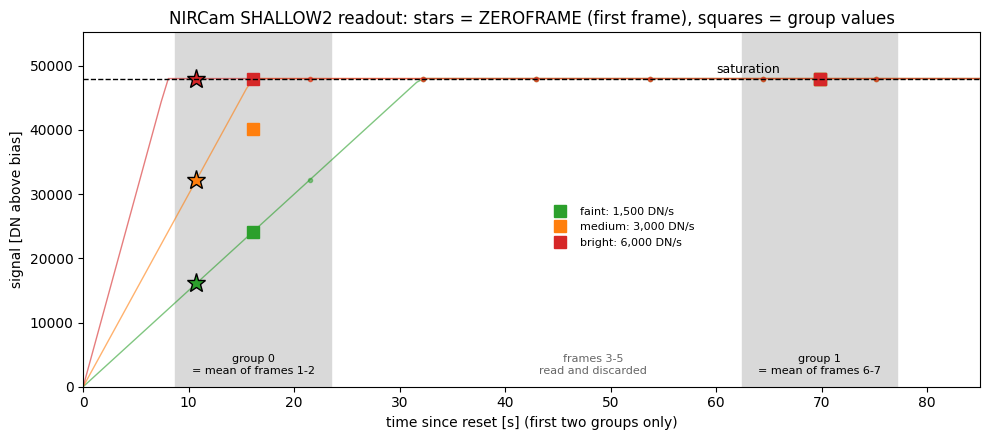

In [3]:
TFRAME, W = 10.737, 48000          # frame time [s]; usable well above bias [DN] (an estimate)
frames = np.arange(1, 26)           # frame k is read at k * TFRAME
group_frames = [(1, 2), (6, 7), (11, 12), (16, 17), (21, 22)]   # SHALLOW2: 2 averaged, 3 skipped
fig, ax = plt.subplots(figsize=(10, 4.5))
t = np.linspace(0, 25 * TFRAME, 400)
for rate, col, name in [(1500, 'C2', 'faint: 1,500 DN/s'), (3000, 'C1', 'medium: 3,000 DN/s'), (6000, 'C3', 'bright: 6,000 DN/s')]:
    ax.plot(t, np.minimum(rate * t, W), color=col, lw=1, alpha=0.6)
    sig = np.minimum(rate * frames * TFRAME, W)
    ax.plot(frames * TFRAME, sig, 'o', color=col, ms=3, alpha=0.5)
    g = [np.mean([min(rate * f * TFRAME, W) for f in fr]) for fr in group_frames]
    ax.plot([np.mean(fr) * TFRAME for fr in group_frames], g, 's', color=col, ms=8, label=name)
    ax.plot(TFRAME, min(rate * TFRAME, W), '*', color=col, ms=14, mec='k')
ax.axhline(W, color='k', ls='--', lw=1)
ax.text(60, W + 900, 'saturation', fontsize=9)
for (a, b), lab in [((1, 2), 'group 0\n= mean of frames 1-2'), ((6, 7), 'group 1\n= mean of frames 6-7')]:
    ax.axvspan(a * TFRAME - 2, b * TFRAME + 2, color='0.85', zorder=0)
    ax.text((a + b) / 2 * TFRAME, 2000, lab, ha='center', fontsize=8)
ax.text(4.5 * TFRAME, 2000, 'frames 3-5\nread and discarded', ha='center', fontsize=8, color='0.4')
ax.set_xlim(0, 85)
ax.set_xlabel('time since reset [s] (first two groups only)')
ax.set_ylabel('signal [DN above bias]')
ax.set_title('NIRCam SHALLOW2 readout: stars = ZEROFRAME (first frame), squares = group values')
ax.set_ylim(0, W * 1.15)
ax.legend(frameon=False, fontsize=8, loc='center', bbox_to_anchor=(0.6, 0.45))
plt.tight_layout()

**Reading the figure.**

* **Faint star (green):** group 0 is unsaturated; the pixel would not be level 0 at all.
* **Medium star (orange):** the second frame of group 0 is saturated but the first is not. Group 0 is flagged, yet the ZEROFRAME (star symbol) still measures the flux: rate = ZEROFRAME / 10.7 s.
* **Bright star (red):** every frame is saturated, including the ZEROFRAME. The ramp holds no flux information; only the star's unsaturated wings do.

The subagents measured how level-0 rows split (rows with `psf_share` > 0.75; NIRCam from a sample of about 9,900 of 37,500 rows, MIRI complete; v2 tables):

| type | NIRCam | MIRI | what is left in the ramp | expected accuracy (dex) |
| --- | --- | --- | --- | --- |
| **A-hard**: above threshold, ZEROFRAME saturated too | 19% | - | nothing (NIRCam) | 0.30, no better than guessing per filter |
| **A-soft**: above threshold, ZEROFRAME unsaturated | 11% | - | the ZEROFRAME | 0.13 |
| **A (MIRI)**: above threshold | - | 60% | a slow rise toward a ceiling (item 3) | 0.29 |
| **B**: 75-100% of threshold, NIRCam averaging rule | 23% | n/a | a normal group-0 readout | 0.14 |
| **C**: below threshold, flagged only as a neighbour | 46% | 40% | a normal group-0 readout | 0.11-0.18 |

So about 70% of NIRCam "level-0" pixels and 40% of MIRI ones are not saturated in their first readout.

**Proposal.** For every labelled level-0 pixel, compare its raw first readout (from the `_uncal` file) with its own saturation threshold (CRDS `SATURATION` reference file), check the ZEROFRAME for NIRCam, and store the type in a new column `l0_type` (A-hard / A-soft / A / B / C).

**Cost.** About 30 lines in `making_training_set.py` (read the `_uncal` file and the reference file per exposure), plus the rerun.

**Your decision.** Go or no go.

## 3. Two new features: the NIRCam ZEROFRAME and the MIRI step ratios

**In short.** For NIRCam, the ZEROFRAME is the best single clue for many level-0 pixels but is not in the tables. For MIRI, the shape of the ramp after saturation carries the flux, and ratios of its steps describe that shape best.

**3a. NIRCam ZEROFRAME.** The pipeline sets the processed ZEROFRAME to 0 for flagged pixels, so it never reaches the ramp file; the raw `_uncal` file keeps it. To use it, subtract the pixel's bias (CRDS `SUPERBIAS`) and the reference-pixel offset; the rate is then ZEROFRAME / TFRAME. The subagent's test: for type C pixels, the ZEROFRAME alone reached 0.113 dex, better than all current ramp features together (0.127 dex). It is the only way to restore type A-soft pixels.

**3b. MIRI step ratios.** A MIRI pixel that saturates does not stop rising. As charge collects, the voltage across the pixel drops ("debiasing"), its response falls, and the ramp creeps toward a common ceiling near 62,000 DN. A brighter pixel gets there faster, so its later steps are smaller. The figure groups the truly saturated MIRI level-0 pixels by their label and plots the median rise after group 0.

5,352 MIRI level-0 rows with DN0 > 50,000 and psf_share > 0.75


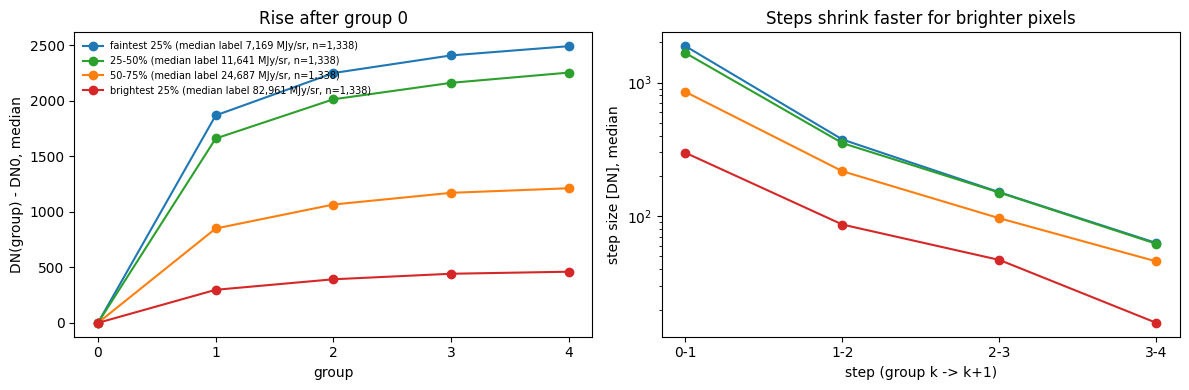

In [4]:
m0 = good[(good.inst == 'MIRI') & (good.sat_level == 0) & (good.DN0 > 50000)].copy()   # DN0 > 50,000: approximately the truly saturated (type A)
m0['label bin'] = pd.qcut(np.log10(m0.flux), 4, labels=['faintest 25%', '25-50%', '50-75%', 'brightest 25%'])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for (name, g), col in zip(m0.groupby('label bin', observed=True), ['C0', 'C2', 'C1', 'C3']):
    rise = np.array([np.median(g[f'DN{k}'] - g.DN0) for k in range(5)])
    axes[0].plot(range(5), rise, 'o-', color=col, label=f'{name} (median label {g.flux.median():,.0f} MJy/sr, n={len(g):,})')
    axes[1].plot(range(4), [np.median(g[f'DN{k + 1}'] - g[f'DN{k}']) for k in range(4)], 'o-', color=col)
axes[0].set_xticks(range(5)); axes[0].set_xlabel('group'); axes[0].set_ylabel('DN(group) - DN0, median'); axes[0].set_title('Rise after group 0')
axes[0].legend(frameon=False, fontsize=7)
axes[1].set_xlabel('step (group k -> k+1)'); axes[1].set_ylabel('step size [DN], median'); axes[1].set_yscale('log')
axes[1].set_title('Steps shrink faster for brighter pixels'); axes[1].set_xticks(range(4)); axes[1].set_xticklabels(['0-1', '1-2', '2-3', '3-4'])
plt.tight_layout()
print(f'{len(m0):,} MIRI level-0 rows with DN0 > 50,000 and psf_share > 0.75')

The plateau value itself is about the same for every pixel and carries no flux; what differs is how quickly the steps shrink. Ratios such as (DN2 - DN1) / (DN1 - DN0) describe that, and they cancel the shared ceiling. The subagent found that the steps alone cut the MIRI level-0 error from 0.46 dex (guessing per filter) to 0.33 dex. Most of the gain ranks pixels within a star; the star's overall brightness still needs the wings.

**Proposal.** 3a: add a column `zeroframe_rate` for NIRCam (and the bias-subtracted ZEROFRAME). 3b: compute the step ratios when assembling the input; they need no new data.

**Cost.** 3a: about 20 lines plus the rerun, bundled with item 2 (it reads the same `_uncal` file). 3b: a few lines at assembly.

**Your decision.** Go or no go for each.

## 4. Bad-pixel flags: NO_LIN_CORR, and DEAD treated like HOT

**In short.** Pixels the pipeline marks as bad give misleading ramps. They are rare in the current tables, so excluding them costs little; the bigger question is DEAD pixels, which still drop whole stars.

**Background.** Every pixel carries data-quality (DQ) flags. Relevant ones:

* **HOT**: high dark current. Now left out of the labels while the rest of the star is kept (done in v3).
* **DEAD**: does not respond. Any DEAD pixel in a star's saturated region still drops the *whole* star: 3,823 stars in v3, the second-largest skip reason after faint models.
* **NO_LIN_CORR**: no non-linearity correction exists for the pixel, so its ramp values are not corrected and its features mean something different from other pixels'.

The physics subagent saw one NIRCam detector (nrca1) where 99% of the group-0-saturated pixels were bad. That count included clusters of bad pixels that are not stars; v3 already skips those. Measured on the v3 tables (2026-10-22, flags read from each pixel's `cal` file):

| | NIRCam level 0 | NIRCam levels 1-4 | MIRI |
| --- | --- | --- | --- |
| NO_LIN_CORR | 0.84% | 0.15-0.37% | 0 |
| any bad-pixel flag | 1.4% | 0.8-1.0% | < 0.1% |
| rows lost with `psf_share` > 0.75 | 298 | 2,502 | 0 |

Detector nrca1 is the worst case: 7.3% of its level-0 rows are NO_LIN_CORR.

**Proposal.** (a) Store each pixel's DQ value in a column `pixel_dq`, so any flag can be filtered at assembly time; exclude NO_LIN_CORR there. (b) Treat DEAD like HOT: leave DEAD pixels out of the labels, keep the rest of the star.

**Cost.** Two short code changes plus the rerun.

**Your decision.** Exclude NO_LIN_CORR (proposed: yes, about 2,800 rows); DEAD like HOT (proposed: yes).

## 5. Check the level-0 labels themselves

**In short.** We have checked the labels only at levels 2-4, where the pipeline gives an independent value. Level-0 labels sit in the cores of the brightest stars, where the PSF fit has to extrapolate furthest, and nothing has checked them yet. A model can only be as good as these labels.

**Background.** A level-0 label is the PSF model's prediction at the very centre of a star whose centre is masked. Three things can make it wrong there: the PSF model's core shape, a small error in the fitted centre (the core is steep, so 0.1 px moves the core value a lot), and effects the PSF model leaves out (charge spreading into neighbours in very bright pixels). Three tests, from cheapest to most complete:

| test | idea | what it measures | data needed | effort |
| --- | --- | --- | --- | --- |
| **a. repeat across dithers** | the same star is observed in several exposures; its fitted total flux should agree | the overall error floor of a star's flux | v3 tables + each exposure's sky coordinates | half a day; no rerun |
| **b. centre shifts** | move the fitted centre by 0.05 and 0.1 px and recompute the core labels | how much centroid error moves the core labels | v3 fits redone for a sample | about a day |
| **c. injection** | take a star whose core is well measured, scale it up until the core saturates, mask the core as the pipeline would, refit, compare with the known flux | the bias of the method for exactly the level-0 case | unsaturated or level 2-4 stars | a few days |

**Proposal.** Start with (a), which needs no new fitting; then (b); then (c), the real test.

**Cost.** As in the table; none needs the rerun, so (a) can start now.

**Your decision.** Which tests, and in which order.

## 6. Assemble the training input

**In short.** One short script turns the 480 tables into the model's training set: keep reliable rows, choose the target, remove features that leak the answer, and balance the levels.

**Steps.**

1. **Keep reliable rows:** `psf_share` > 0.75 (decided); `area_ratio` <= 4 for MIRI if item 1 is accepted; no NO_LIN_CORR if item 4 is accepted.
2. **Targets:** the PSF label `flux` for every level; for levels 2-4 also `cal_value` (decided: both are kept, so two models or two target columns).
3. **Features:** ramp quantities only: `DN0`-`DN4`, slopes, curvatures, `nl_strength`, `max_DN`, `mean_DN`, filter, instrument, detector, `in_4qpm`, `fqpm_quadrant`, plus the new ones from items 2-3.
4. **Leave out:** anything computed from the PSF fit or the label, because the model would learn the answer from it instead of from the ramp: `dist_to_peak`, `is_near_peak`, `psf_star_flux`, `local_bkg`, `area_ratio`, `sidelobe_residual_snr`, `psf_share`, `fluxerr`, `x`, `y`.
5. **Cap per star:** at most N rows per (star, level), for example N = 30, so a few large stars do not dominate.
6. **Balance:** the same number of rows per level, separately for NIRCam and MIRI (MIRI is much smaller).

Rows available after the `psf_share` cut (v3):

In [5]:
left = good.groupby(['inst', 'sat_level']).size().unstack().fillna(0).astype(int)
left['stars'] = good.groupby('inst').source_id.nunique()
left

sat_level,0.0,1.0,2.0,3.0,4.0,stars
inst,,,,,,
MIRI,7593,5670,2980,1877,0,417
NIRCam,45712,396402,193797,152962,129003,32928


**Cost.** One script, about 50 lines; no rerun.

**Your decision.** The cap N (proposed 30) and whether levels are balanced exactly or only capped.

## 7. Evaluation protocol

**In short.** How we test the model decides whether its score means anything. Two traps would make a weak model look good: seeing the same star in training and test, and testing only on stars no brighter than the training stars.

**Trap 1: the same star twice.** Each star is observed in several exposures (dithers) and in several filters. If one exposure of a star is in training and another in the test set, the model has effectively seen the answer. **Split by sky position**: group all detections within about 1 arcsec into one "star", and keep each star entirely in training or entirely in test.

**Trap 2: brighter than anything seen.** Level-0 labels are much brighter than the rest, and tree models such as gradient boosting cannot predict above the largest value they were trained on. The figure shows how far level 0 reaches beyond the other levels.

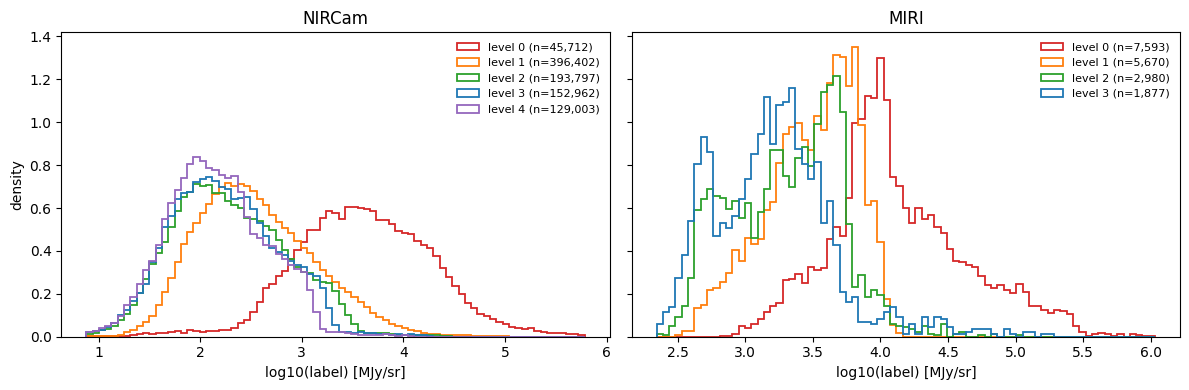

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, inst in zip(axes, ['NIRCam', 'MIRI']):
    h = good[good.inst == inst]
    bins = np.linspace(np.log10(h.flux).quantile(0.001), np.log10(h.flux).quantile(0.9999), 80)
    for lvl, col in zip(range(5), ['C3', 'C1', 'C2', 'C0', 'C4']):
        x = np.log10(h[h.sat_level == lvl].flux)
        if len(x):
            ax.hist(x, bins=bins, histtype='step', lw=1.3, color=col, density=True, label=f'level {lvl} (n={len(x):,})')
    ax.set_xlabel('log10(label) [MJy/sr]'); ax.set_title(inst); ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel('density')
plt.tight_layout()

**Proposal.**

* **Split:** by sky position, 5 folds.
* **Extra test set:** hold out the brightest 20% of stars in each filter, to see what happens beyond the training range.
* **Scores**, reported per instrument, per level, and per level-0 type (item 2):
  * the typical error, as the 16-84% spread of log10(prediction / label) in dex;
  * the fraction of pixels within 10% and within a factor 1.5;
  * the slope of log(prediction) against log(label). A slope of 1 means no ceiling; a slope below 1 means the model flattens out for bright stars.
* **Baselines the model must beat:** the median label per filter; a simple fit on DN0 and filter; the same model trained without level 0.
* **Shuffle test:** shuffle the ramp features among level-0 pixels of the same filter. If the score does not get worse, the ramp was not being used.

**Cost.** Part of the first training script.

**Your decision.** The held-out fraction (proposed 20%) and the number of folds.

## 8. Small cleanups

* **"Flux change > 20%" check.** After each fit, the code replaces the saturated pixels with the model and compares the total of the *unsaturated* pixels before and after. The replacement never touches those pixels, so the totals always match and the check has never fired (0 of 62,714 sources). **Proposal:** delete it.
* **Run script queue.** `script/run_making_training_set.sh` asks for the burst queue (`astronomy-dept-b`) and 96 hours; jobs waited there for over an hour, while the main queue (`astronomy-dept`, 4 hours) started them within minutes and every job finished in under 2.5 hours. **Proposal:** switch the script to the main queue with a 4-hour limit.
* **Notes.** Question 16 of `discussion_20261021.ipynb` still lists items 7 and 8 of that list as open; v3 has answered them (`report_v3_training_set_20261021.ipynb`).

**Cost.** A few lines; the check deletion goes into the rerun.

**Your decision.** Both proposals: yes or no.